In [1]:
import pathlib

import navis.interfaces.neuprint as neu
from matplotlib import pyplot as plt

import el_hd_plasticity.connectomics as cn
from el_hd_plasticity.connectomics import plotting
from el_hd_plasticity.connectomics import synapse_distance as sd
from el_hd_plasticity.connectomics.run_epg_instance_distance import get_er_epg_synapses

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_connectomics')
figfolder.mkdir(parents=True, exist_ok=True)
syndist_folder = figfolder / 'syn_distances'      # written by el_hd_plasticity.connectomics.run_epg_instance_distance
client = cn.npt_client()

## Distance between the synapses of an ER neuron onto EPG neurons of different EB columns

For every synapse of an ER neuron onto an EPG neuron (a presynaptic site on the ER neuron), the cable distance along the ER neuron to the
nearest synapse onto an EPG of a *different EB column*, computed by `python -m el_hd_plasticity.connectomics.run_epg_instance_distance`.
The two EPG instances that innervate the same wedge are treated as one column (`EPG(PB08)_L3` and `EPG(PB08)_R7` are both `L3/R7`),
paired as in [Hulse et al. 2021](https://elifesciences.org/articles/66039/figures#content): R1=L1, R2=L8, R3=L7, R4=L6, R5=L5, R6=L4,
R7=L3, R8=L2. That leaves eight columns rather than sixteen instances, so the nearest different group is never the mirror image of the
synapse's own column. Paths are not length-limited; the histograms use the 0-16 micron scale and bins of the EL distance analyses
(`synapse_distance.ipynb`).


### Example ER4d axon

In [2]:
ebcoords = cn.EBCoordinateSystem()
eb = ebcoords.fetch_roi('EB')

ers, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type='ER4d'))
example_er4d = ers['bodyId'].iloc[3]
er4d_skeleton = ebcoords.fetch_skeleton(example_er4d)

syns, _ = get_er_epg_synapses('ER4d')
syns = cn.add_eb_coords(syns.loc[syns['bodyId_pre'] == example_er4d].copy(), ebcoords, type='pre')

# the most-synapsed column and the two columns whose synapses lie closest to it
columns = sd.adjacent_instances(syns)

print(syns['type'].value_counts().to_dict())


/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/connectomics/connectomics.py:250: UserWarning: 
The coefficients of the spline returned have been computed as the
minimal norm least-squares solution of a (numerically) rank deficient
system (deficiency=92). If deficiency is large, the results may be
inaccurate. Deficiency may strongly depend on the value of eps.
  self._xsec_rad_spline = sp.interpolate.LSQBivariateSpline(eb_phase, xsec_phase, xsec_rad, knots, knots)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (20 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

{'L8/R2': 56, 'L1/R1': 54, 'L3/R7': 48, 'L6/R4': 46, 'L2/R8': 46, 'L7/R3': 44, 'L4/R6': 40, 'L5/R5': 30}


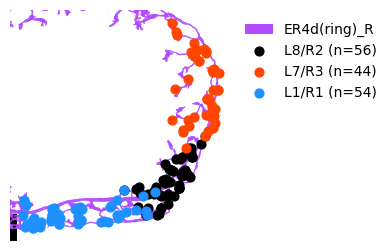

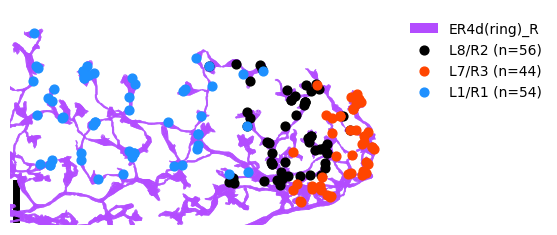

In [3]:
for plane in ('xy', 'xz'):
    fig, ax = plotting.plot_instance_example(er4d_skeleton, syns, columns, view=tuple(plane))
    fig.savefig(figfolder / f'er4d_epg_column_synapses_{plane}.png', dpi=500, transparent=True, bbox_inches='tight')


### Example axons of the other ER types

One neuron per type, with the synapses of its most-synapsed column and the two columns whose synapse centroids are closest to it.


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/14903 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (79 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

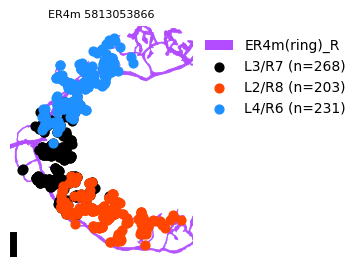

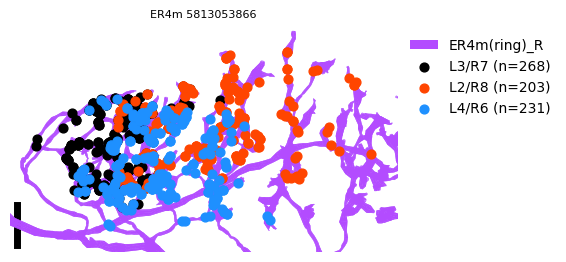

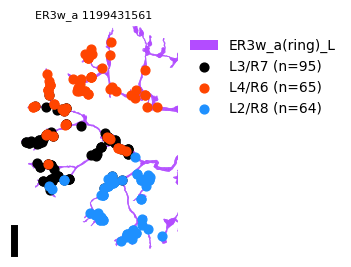

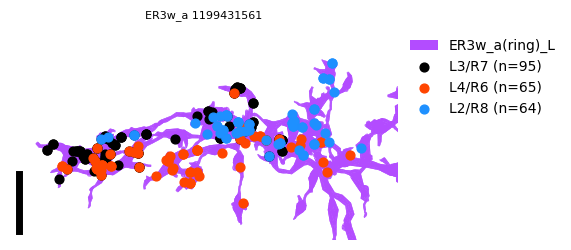

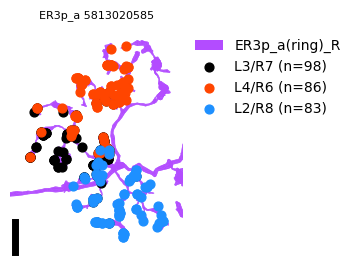

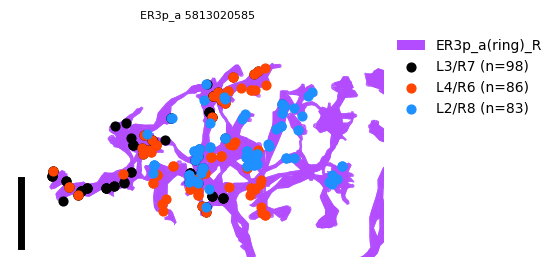

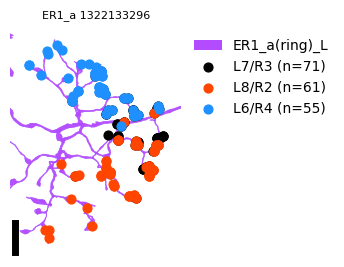

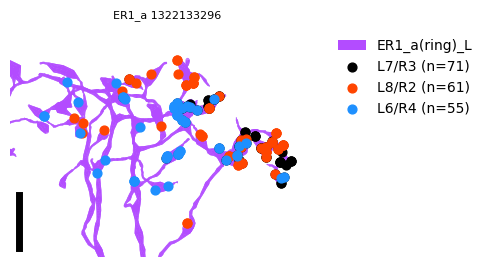

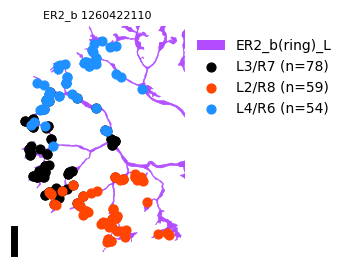

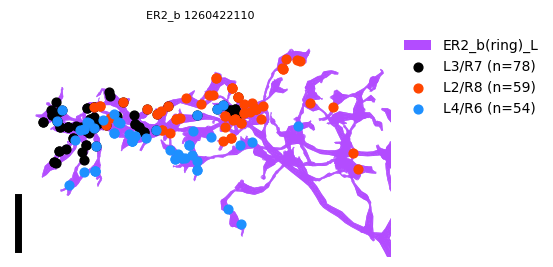

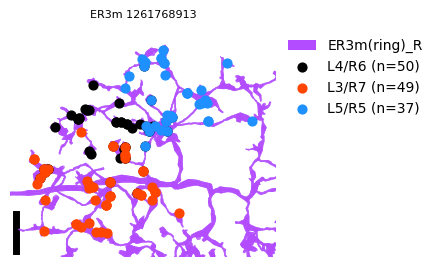

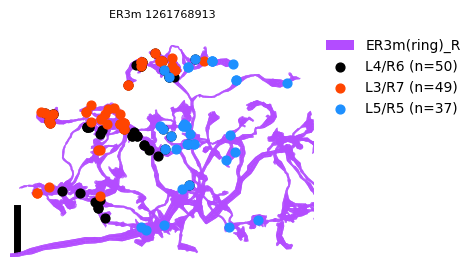

In [4]:
for er_type in ('ER4m', 'ER3w_a', 'ER3p_a', 'ER1_a', 'ER2_b', 'ER3m'):
    er_syns, _ = get_er_epg_synapses(er_type)
    body_id = er_syns['bodyId_pre'].value_counts().index[0]            # the neuron with most synapses
    er_syns = cn.add_eb_coords(er_syns.loc[er_syns['bodyId_pre'] == body_id].copy(), ebcoords, type='pre')
    er_columns = sd.adjacent_instances(er_syns)
    skeleton = ebcoords.fetch_skeleton(body_id)
    for plane in ('xy', 'xz'):
        fig, ax = plotting.plot_instance_example(skeleton, er_syns, er_columns, view=tuple(plane))
        ax.set_title(f'{er_type} {body_id}', fontsize=8)
        fig.savefig(figfolder / f'{er_type}_epg_column_synapses_{plane}.png', dpi=500, transparent=True, bbox_inches='tight')


### Distances

In [5]:
distance_df = sd.load_instance_distance_table(syndist_folder, sd.ER_TYPES)
summary = distance_df.groupby('er')['distances'].agg(
    synapses='size', columns=lambda d: distance_df.loc[d.index, 'group'].nunique(),
    fraction_with_a_partner=lambda d: d.notna().mean(), median_microns='median').round(2)
print(summary.loc[list(sd.ER_TYPES)])


        synapses  columns  fraction_with_a_partner  median_microns
er                                                                
ER4d       10000        8                      1.0           13.62
ER4m       14903        8                      1.0            2.86
ER2_a       5091        8                      1.0            6.70
ER2_b       3073        8                      1.0            3.12
ER2_c      12671        8                      1.0            8.01
ER2_d       3249        8                      1.0            5.65
ER3w_b      5874        8                      1.0            1.18
ER3a_c       595        8                      1.0            3.99
ER3p_a      7053        8                      1.0            0.92
ER3w_a      4723        8                      1.0            1.72
ER3a_b        74        8                      1.0           27.74
ER3p_b      2532        8                      1.0            1.61
ER3d_c      2494        8                      1.0            

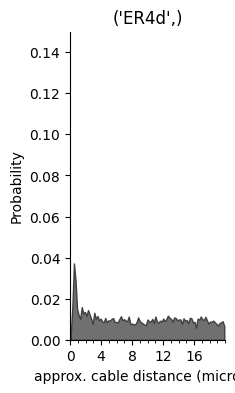

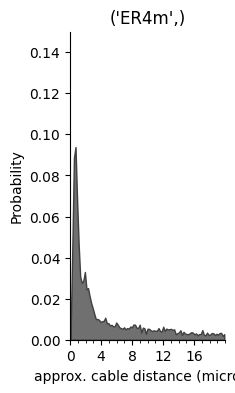

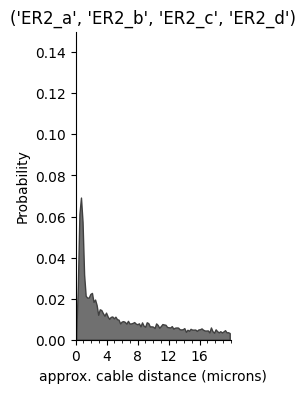

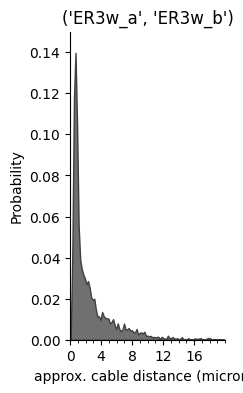

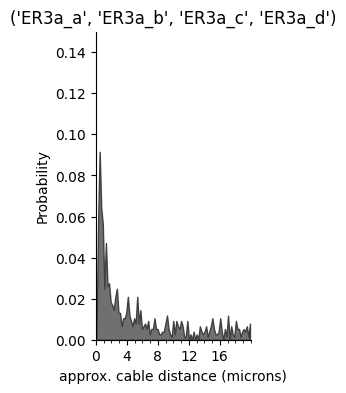

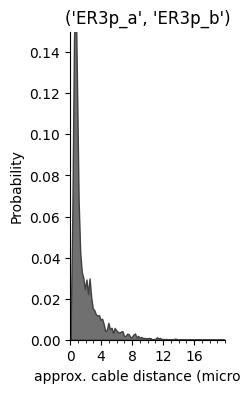

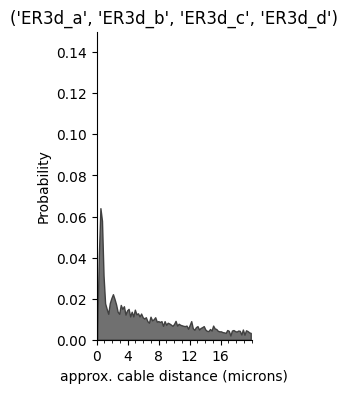

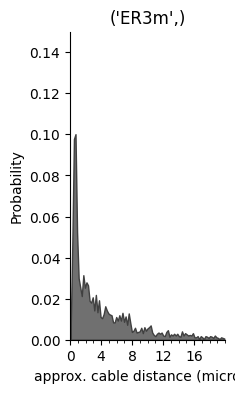

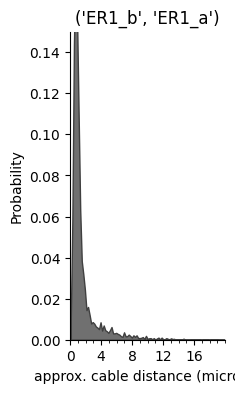

In [12]:
import numpy as np

bins = np.linspace(0,20,100)
xlims = [0,20]
for i, group in enumerate(sd.ER_GROUPS):

    fig, ax = plotting.plot_family_distance_histogram(distance_df, group, bins=bins, xlims=xlims, source='epg_column', color=plt.cm.Greys(.8))
    fig.savefig(figfolder / f'group{i}_epg_column_dist.pdf')


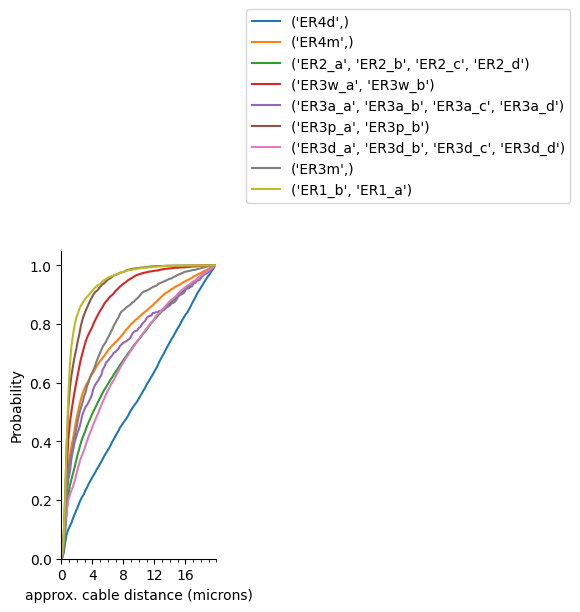

In [11]:
fig, axs = plotting.plot_cumulative_distances(distance_df, sd.ER_GROUPS, bins=bins, xlims=[0,20], sources=('epg_column',), figsize=(2, 4))
fig.savefig(figfolder / 'all_epg_column_dist_cumulative.pdf', bbox_inches='tight')
